In [24]:
#  !pip install kagglehub

# Heart Disease Exploratory Data Analysis (EDA)
This notebook analyzes the Statlog (Heart Disease) dataset to explore relationships between clinical features and heart disease risk.

In [25]:
# Import libraries
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Styling for plots
%matplotlib inline
sns.set_theme(style="whitegrid")

## 1. Data Loading
Downloading and loading the dataset using Kagglehub.

In [26]:
# Download latest version of the dataset
path = kagglehub.dataset_download("ritwikb3/heart-disease-statlog")

# Load data into Pandas DataFrame
df = pd.read_csv(f"{path}/Heart_disease_statlog.csv")

# Preview the first rows
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0


## 2. Data Cleaning & Mapping
Renaming columns to clear descriptions and mapping categorical values to readable labels.

In [28]:
# Rename columns for clarity
new_column_names = {
    'age': 'age',
    'sex': 'sex',
    'cp': 'chest_pain_type',
    'trestbps': 'resting_blood_pressure',
    'chol': 'cholesterol',
    'fbs': 'fasting_blood_sugar',
    'restecg': 'resting_ecg',
    'thalach': 'max_heart_rate',
    'exang': 'exercise_angina',
    'oldpeak': 'st_depression',
    'slope': 'st_slope',
    'ca': 'major_vessels',
    'thal': 'thalassemia',
    'target': 'heart_disease'
}

df = df.rename(columns=new_column_names)

# Map categorical values for better readability
df['sex'] = df['sex'].map({1: 'male', 0: 'female'})
df['heart_disease_label'] = df['heart_disease'].map({1: 'yes', 0: 'no'})

# Check cleaned data
df.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,major_vessels,thalassemia,heart_disease,heart_disease_label
0,70,male,3,130,322,0,2,109,0,2.4,1,3,1,1,yes
1,67,female,2,115,564,0,2,160,0,1.6,1,0,3,0,no
2,57,male,1,124,261,0,0,141,0,0.3,0,0,3,1,yes
3,64,male,3,128,263,0,0,105,1,0.2,1,1,3,0,no
4,74,female,1,120,269,0,2,121,1,0.2,0,1,1,0,no


## 3. Exploratory Data Analysis (EDA) & Visualizations

### Question 1: How does age affect heart disease risk?

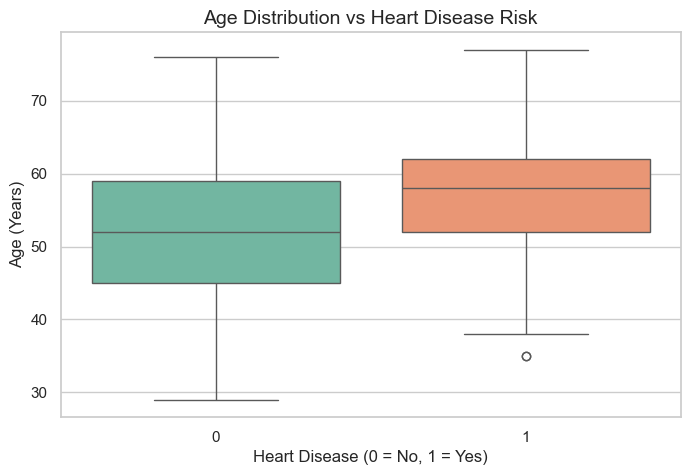

In [30]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='heart_disease', y='age', data=df, hue='heart_disease', palette='Set2', legend=False)

plt.title('Age Distribution vs Heart Disease Risk', fontsize=14)
plt.xlabel('Heart Disease (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Age (Years)', fontsize=12)
plt.show()

### Question 2: Do high cholesterol levels increase heart disease risk?

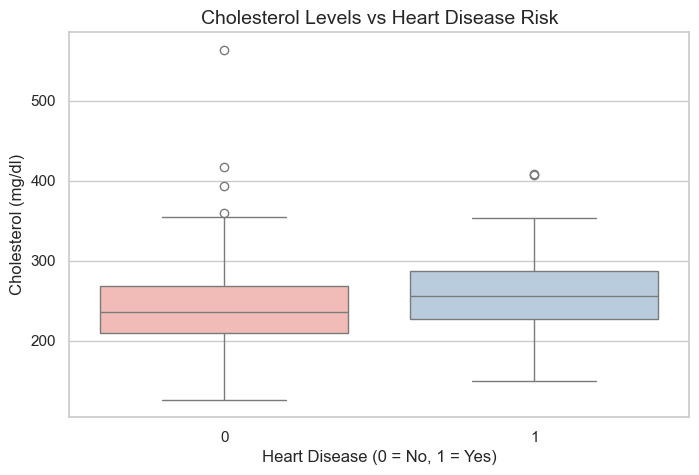

In [32]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='heart_disease', y='cholesterol', data=df, hue='heart_disease', palette='Pastel1', legend=False)

plt.title('Cholesterol Levels vs Heart Disease Risk', fontsize=14)
plt.xlabel('Heart Disease (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Cholesterol (mg/dl)', fontsize=12)
plt.show()

### Question 3: What do chest pain types tell us about heart disease?

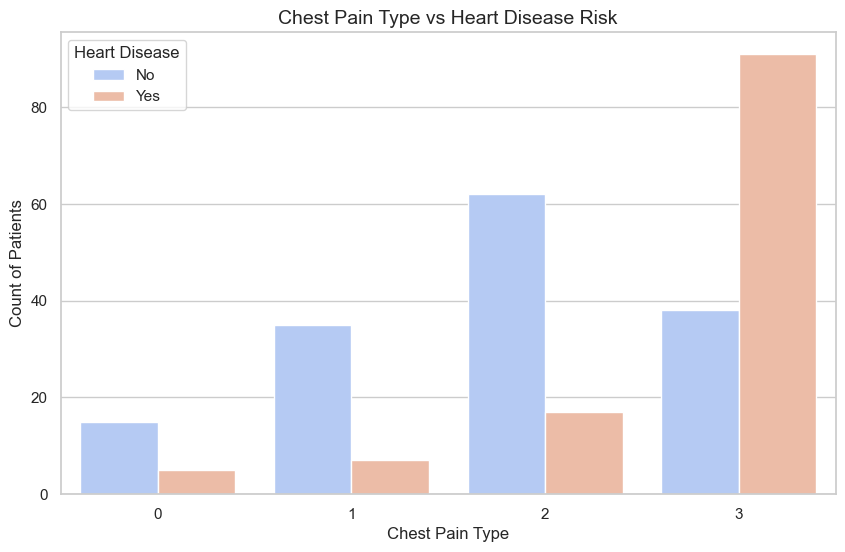

In [33]:
plt.figure(figsize=(10, 6))
sns.countplot(x='chest_pain_type', hue='heart_disease', data=df, palette='coolwarm')

plt.title('Chest Pain Type vs Heart Disease Risk', fontsize=14)
plt.xlabel('Chest Pain Type', fontsize=12)
plt.ylabel('Count of Patients', fontsize=12)
plt.legend(title='Heart Disease', labels=['No', 'Yes'])
plt.show()